# Multiclass Classification with Logistic Regression

This notebook demonstrates three projects using **scikit-learn Logistic Regression**:

1. Iris Flower Classification
2. Handwritten Digit Classification (`scikit-learn` digits dataset)
3. Fashion-MNIST Classification

Each project includes data loading, EDA, preprocessing, train-test split, model training, evaluation, confusion matrix, predictions, and saving the model and related artifacts.

**Requirements:** `pandas`, `numpy`, `matplotlib`, `seaborn`, `scikit-learn`, `joblib`.

# Project 1 — Iris Flower Classification

## 1. What is multiclass classification?

- **Goal:** Predict one class from three flower species.
- **Features:** Sepal length, sepal width, petal length, petal width.
- **Target:** Iris species (`setosa`, `versicolor`, `virginica`).
- Logistic Regression estimates class probabilities, then predicts the class with the highest probability.

For class \(k\), the softmax function converts class scores into probabilities:

\[
P(y=k\mid x)=\frac{e^{z_k}}{\sum_{j=1}^{K}e^{z_j}}
\]

where \(z_k=w_k^Tx+b_k\), and \(K\) is the number of classes.

The predicted class is:

\[
\hat{y}=\arg\max_k P(y=k\mid x)
\]

- **Accuracy:** proportion of correct predictions.
\[
\text{Accuracy}=\frac{\text{Correct Predictions}}{\text{Total Predictions}}
\]

## 2. Import Libraries

In [17]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.datasets import load_iris, load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

ARTIFACT_DIR = Path("artifacts")
ARTIFACT_DIR.mkdir(exist_ok=True)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

In [3]:
p = Path("output")

In [6]:
p.mkdir(exist_ok=True)

## 3. Load Data and Inspect

In [19]:
iris = load_iris(as_frame=True)

In [24]:
iris.data

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2
...,...,...,...,...
145,6.7,3.0,5.2,2.3
146,6.3,2.5,5.0,1.9
147,6.5,3.0,5.2,2.0
148,6.2,3.4,5.4,2.3


In [25]:
iris.target

0      0
1      0
2      0
3      0
4      0
      ..
145    2
146    2
147    2
148    2
149    2
Name: target, Length: 150, dtype: int32

In [26]:
iris.frame

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


In [27]:
iris_df = iris.frame.copy()

In [28]:
iris_df.rename(columns={"target": "target_id"})

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target_id
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


In [29]:
iris_df

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


In [40]:
iris_df["species"] = iris_df['target'].map(dict(enumerate(iris.target_names)))

In [41]:
iris_df

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa
...,...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2,virginica
146,6.3,2.5,5.0,1.9,2,virginica
147,6.5,3.0,5.2,2.0,2,virginica
148,6.2,3.4,5.4,2.3,2,virginica


In [43]:
iris_df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target_id,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [42]:
iris = load_iris(as_frame=True)
iris_df = iris.frame.copy()

# Rename the target column for clarity
iris_df = iris_df.rename(columns={"target": "target_id"})
iris_df["species"] = iris_df["target_id"].map(dict(enumerate(iris.target_names)))

display(iris_df.head())
print("Shape:", iris_df.shape)
print("\\nDataset information:")
iris_df.info()
display(iris_df.describe())
print("\\nMissing values per column:")
print(iris_df.isnull().sum())
print("\\nDuplicate rows:", iris_df.duplicated().sum())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target_id,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


Shape: (150, 6)
\nDataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target_id          150 non-null    int32  
 5   species            150 non-null    object 
dtypes: float64(4), int32(1), object(1)
memory usage: 6.6+ KB


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target_id
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


\nMissing values per column:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target_id            0
species              0
dtype: int64
\nDuplicate rows: 1


## 4. EDA — Class Counts and Feature Relationships

In [68]:
(iris_df['target_id'] == 0).sum()

50

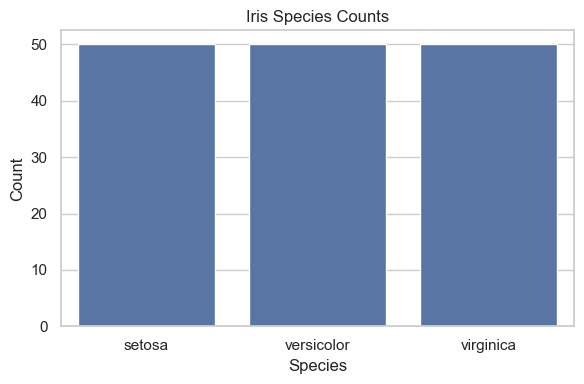

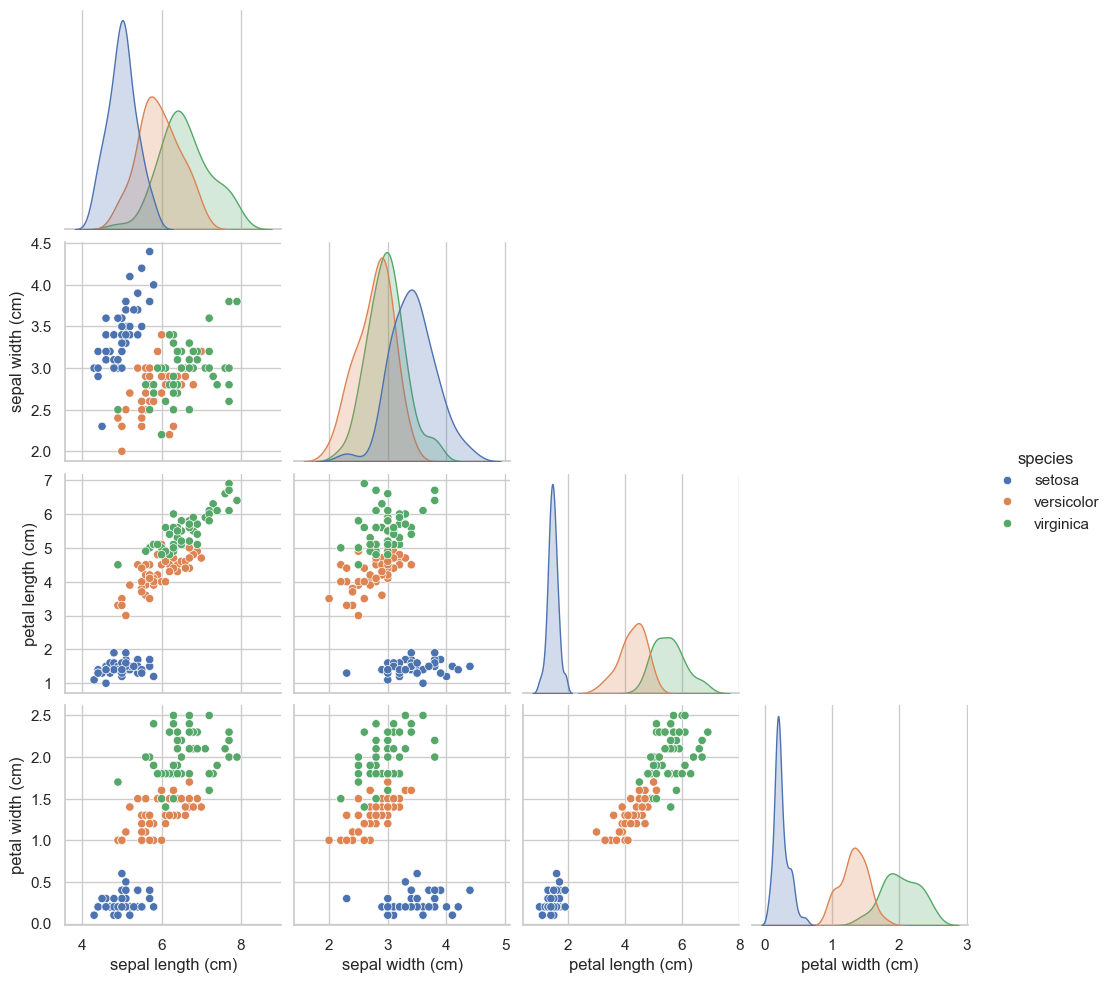

In [44]:
plt.figure(figsize=(6, 4))
sns.countplot(data=iris_df, x="species")
plt.title("Iris Species Counts")
plt.xlabel("Species")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

sns.pairplot(iris_df, vars=iris.feature_names, hue="species", corner=True)
plt.show()

## 5. Preprocessing and Train-Test Split

In [45]:
iris.data

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2
...,...,...,...,...
145,6.7,3.0,5.2,2.3
146,6.3,2.5,5.0,1.9
147,6.5,3.0,5.2,2.0
148,6.2,3.4,5.4,2.3


In [46]:
# The built-in Iris dataset has no missing values or duplicate rows.
# Features (X) are measurements; target (y) is the numeric class label.
X = iris.data.copy()
y = iris.target.copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

# StandardScaler is fit on training data only.
# Pipeline prevents data leakage and applies the same scaling at prediction time.
iris_model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic_regression", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])

Training samples: 120
Testing samples: 30


## 6. Train the Model

In [47]:
iris_model.fit(X_train, y_train)
print("Training complete.")

Training complete.


## 7. Evaluate the Model

In [48]:
y_pred = iris_model.predict(X_test)

print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")

Accuracy: 0.9333


In [53]:
y_pred_train = iris_model.predict(X_train)

print(f"Training Accuracy : {accuracy_score(y_train, y_pred_train)*100:.2f}%")

Training Accuracy : 95.83%


In [54]:
y_test_prob = iris_model.predict_proba(X_test)

In [60]:
y_test

38     0
127    2
57     1
93     1
42     0
56     1
22     0
20     0
147    2
84     1
107    2
141    2
104    2
51     1
7      0
49     0
14     0
69     1
63     1
138    2
10     0
140    2
58     1
134    2
132    2
77     1
75     1
18     0
116    2
28     0
Name: target, dtype: int32

In [59]:
y_pred

array([0, 2, 1, 1, 0, 1, 0, 0, 2, 1, 2, 2, 2, 1, 0, 0, 0, 1, 1, 2, 0, 2,
       1, 1, 2, 2, 1, 0, 2, 0])

In [58]:
y_test_prob.argmax(axis=1)

array([0, 2, 1, 1, 0, 1, 0, 0, 2, 1, 2, 2, 2, 1, 0, 0, 0, 1, 1, 2, 0, 2,
       1, 1, 2, 2, 1, 0, 2, 0], dtype=int64)

In [64]:
y_test_prob[0].max()

0.9788180050826804

In [70]:
print("\\nClassification report:")
print(classification_report(y_test, y_pred, target_names=iris.target_names))

\nClassification report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



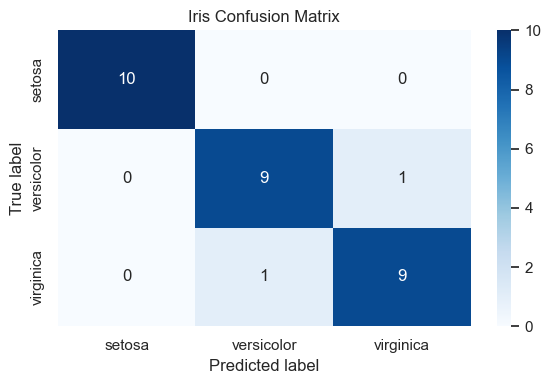

In [69]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("Iris Confusion Matrix")
plt.tight_layout()
plt.show()

## 8. Multiclass Prediction

In [72]:
sample = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=iris.feature_names
)

sample

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2


In [73]:
# Predict the species for one example using its four measurements.


predicted_id = int(iris_model.predict(sample)[0])
probabilities = iris_model.predict_proba(sample)[0]

print("Predicted species:", iris.target_names[predicted_id])
print("\\nClass probabilities:")
display(pd.DataFrame({
    "Species": iris.target_names,
    "Probability": probabilities
}).sort_values("Probability", ascending=False))

Predicted species: setosa
\nClass probabilities:


,Species,Probability
0,setosa,9.808127e-01
1,versicolor,1.918699e-02
2,virginica,2.696811e-07


## 9. Save Model and Related Artifacts

In [74]:
joblib.dump(iris_model, ARTIFACT_DIR / "iris_logistic_regression.joblib")
np.savez(
    ARTIFACT_DIR / "iris_test_results.npz",
    y_test=y_test.to_numpy(), y_pred=y_pred
)
with open(ARTIFACT_DIR / "iris_metadata.json", "w", encoding="utf-8") as f:
    json.dump({
        "project": "Iris Flower Classification",
        "feature_names": list(iris.feature_names),
        "class_names": list(iris.target_names),
        "accuracy": float(accuracy_score(y_test, y_pred)),
        "random_state": RANDOM_STATE
    }, f, indent=2)

print("Saved model, test predictions, and metadata in:", ARTIFACT_DIR.resolve())

Saved model, test predictions, and metadata in: D:\AI\Courses\Huawei_HCCDA_AI_Course\week_06\sunday\notebooks\artifacts


# Project 2 — Handwritten Digit Classification

Uses `sklearn.datasets.load_digits()` — a small built-in dataset of 8×8 grayscale images of digits 0–9. No external download is needed.

## 1. Load Data and Perform EDA

In [ ]:
digits = load_digits()
X_digits = digits.data
y_digits = digits.target

print("Feature matrix shape:", X_digits.shape)
print("Target shape:", y_digits.shape)
print("Classes:", np.unique(y_digits))
print("Pixel value range:", X_digits.min(), "to", X_digits.max())
print("Missing values:", np.isnan(X_digits).sum())

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for ax, image, label in zip(axes.ravel(), digits.images[:10], y_digits[:10]):
    ax.imshow(image, cmap="gray")
    ax.set_title(f"Label: {label}")
    ax.axis("off")
plt.suptitle("Sample Handwritten Digits")
plt.tight_layout()
plt.show()

pd.Series(y_digits).value_counts().sort_index().plot(kind="bar", figsize=(7, 4))
plt.title("Digit Class Counts")
plt.xlabel("Digit")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

## 2. Split Data and Build the Model

In [ ]:
X_train_digits, X_test_digits, y_train_digits, y_test_digits = train_test_split(
    X_digits, y_digits, test_size=0.2, random_state=RANDOM_STATE, stratify=y_digits
)

digits_model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic_regression", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))
])

digits_model.fit(X_train_digits, y_train_digits)
print("Training samples:", len(X_train_digits))
print("Testing samples:", len(X_test_digits))
print("Training complete.")

## 3. Evaluate the Model

In [ ]:
y_pred_digits = digits_model.predict(X_test_digits)

print(f"Accuracy: {accuracy_score(y_test_digits, y_pred_digits):.4f}")
print("\\nClassification report:")
print(classification_report(y_test_digits, y_pred_digits))

cm_digits = confusion_matrix(y_test_digits, y_pred_digits)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_digits, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted digit")
plt.ylabel("True digit")
plt.title("Handwritten Digits Confusion Matrix")
plt.tight_layout()
plt.show()

## 4. Predict a Digit

In [ ]:
sample_index = 0
sample_digit = X_test_digits[sample_index].reshape(1, -1)
predicted_digit = int(digits_model.predict(sample_digit)[0])
digit_probabilities = digits_model.predict_proba(sample_digit)[0]

plt.imshow(sample_digit.reshape(8, 8), cmap="gray")
plt.title(f"Predicted: {predicted_digit} | Actual: {y_test_digits[sample_index]}")
plt.axis("off")
plt.show()

print("Predicted digit:", predicted_digit)
display(pd.DataFrame({
    "Digit": digits_model.named_steps["logistic_regression"].classes_,
    "Probability": digit_probabilities
}).sort_values("Probability", ascending=False))

## 5. Save Model and Related Artifacts

In [ ]:
joblib.dump(digits_model, ARTIFACT_DIR / "digits_logistic_regression.joblib")
np.savez(
    ARTIFACT_DIR / "digits_test_results.npz",
    y_test=y_test_digits, y_pred=y_pred_digits
)
with open(ARTIFACT_DIR / "digits_metadata.json", "w", encoding="utf-8") as f:
    json.dump({
        "project": "Handwritten Digit Classification (scikit-learn)",
        "image_shape": [8, 8],
        "classes": list(range(10)),
        "accuracy": float(accuracy_score(y_test_digits, y_pred_digits)),
        "random_state": RANDOM_STATE
    }, f, indent=2)

print("Saved model, test predictions, and metadata in:", ARTIFACT_DIR.resolve())

# Project 3 — Fashion-MNIST Classification

Fashion-MNIST contains 28×28 grayscale images from 10 clothing categories. This notebook loads it using `sklearn.datasets.fetch_openml`. The first run downloads the dataset from OpenML and therefore requires internet access.

**Note:** Logistic Regression is a simple baseline for image classification; it is not a deep-learning model.

## 1. Load Data and Perform EDA

In [ ]:
# Fashion-MNIST is loaded directly from OpenML.
# The first run requires internet access and may take some time.
from sklearn.datasets import fetch_openml

fashion = fetch_openml(
    "Fashion-MNIST",
    version=1,
    as_frame=False,
    parser="auto"
)

X_fashion_all = fashion.data
y_fashion_all = fashion.target.astype("int64")

# Reshape the flattened 784-pixel vectors back into 28x28 images for EDA.
X_fashion_images = X_fashion_all.reshape(-1, 28, 28)

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

print("Dataset shape:", X_fashion_all.shape)
print("Target shape:", y_fashion_all.shape)
print("Pixel value range:", X_fashion_all.min(), "to", X_fashion_all.max())
print("Missing values:", np.isnan(X_fashion_all).sum())
print("Number of classes:", len(class_names))

fig, axes = plt.subplots(2, 5, figsize=(10, 5))
for ax, image, label in zip(
    axes.ravel(), X_fashion_images[:10], y_fashion_all[:10]
):
    ax.imshow(image, cmap="gray")
    ax.set_title(class_names[label])
    ax.axis("off")

plt.suptitle("Sample Fashion-MNIST Images")
plt.tight_layout()
plt.show()

pd.Series(y_fashion_all).map(dict(enumerate(class_names))).value_counts().reindex(
    class_names
).plot(kind="bar", figsize=(10, 4))

plt.title("Fashion-MNIST Class Counts")
plt.xlabel("Class")
plt.ylabel("Count")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


## 2. Preprocessing and Train-Test Split

In [ ]:
# Flatten each 28x28 image into 784 pixel features.
# Scale pixel values from 0–255 to 0–1.
X_fashion = X_fashion_all.astype("float32") / 255.0

# Create a stratified train/test split.
X_train_fashion, X_test_fashion, y_train_fashion, y_test_fashion = train_test_split(
    X_fashion,
    y_fashion_all,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y_fashion_all
)

print("Training samples:", len(X_train_fashion))
print("Testing samples:", len(X_test_fashion))
print("Flattened image features:", X_train_fashion.shape[1])


## 3. Train Logistic Regression

In [ ]:
# Multinomial logistic regression across 10 classes.
# This can take a few minutes on a CPU.
fashion_model = LogisticRegression(
    solver="lbfgs",
    max_iter=300,
    random_state=RANDOM_STATE
)

fashion_model.fit(X_train_fashion, y_train_fashion)
print("Training complete.")

## 4. Evaluate on the Official Test Set

In [ ]:
y_pred_fashion = fashion_model.predict(X_test_fashion)

fashion_accuracy = accuracy_score(y_test_fashion, y_pred_fashion)
print(f"Test accuracy: {fashion_accuracy:.4f}")
print("\nClassification report:")
print(classification_report(
    y_test_fashion,
    y_pred_fashion,
    target_names=class_names
))

cm_fashion = confusion_matrix(y_test_fashion, y_pred_fashion)
plt.figure(figsize=(10, 8))
sns.heatmap(
    cm_fashion,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.title("Fashion-MNIST Confusion Matrix")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


## 5. Multiclass Prediction

In [ ]:
sample_index = 0
sample_image = X_test_fashion[sample_index].reshape(28, 28)
sample_features = X_test_fashion[sample_index].reshape(1, -1)

predicted_class = int(fashion_model.predict(sample_features)[0])
fashion_probabilities = fashion_model.predict_proba(sample_features)[0]

plt.imshow(sample_image, cmap="gray")
plt.title(
    f"Predicted: {class_names[predicted_class]} | "
    f"Actual: {class_names[y_test_fashion[sample_index]]}"
)
plt.axis("off")
plt.show()

print("Predicted class:", class_names[predicted_class])
display(pd.DataFrame({
    "Class": class_names,
    "Probability": fashion_probabilities
}).sort_values("Probability", ascending=False))


## 6. Save Model and Related Artifacts

In [ ]:
joblib.dump(
    fashion_model,
    ARTIFACT_DIR / "fashion_mnist_logistic_regression.joblib"
)

np.savez(
    ARTIFACT_DIR / "fashion_mnist_test_results.npz",
    y_test=y_test_fashion,
    y_pred=y_pred_fashion
)

with open(ARTIFACT_DIR / "fashion_mnist_metadata.json", "w", encoding="utf-8") as f:
    json.dump({
        "project": "Fashion-MNIST Classification",
        "dataset_source": "OpenML",
        "image_shape": [28, 28],
        "flattened_features": 784,
        "class_names": class_names,
        "accuracy": float(fashion_accuracy),
        "pixel_scaling": "divide by 255.0",
        "random_state": RANDOM_STATE
    }, f, indent=2)

print("Saved model, test predictions, and metadata in:", ARTIFACT_DIR.resolve())


# Summary

| Project | Dataset | Classes | Input features |
|---|---|---:|---:|
| Iris | scikit-learn | 3 | 4 |
| Handwritten Digits | scikit-learn | 10 | 64 |
| Fashion-MNIST | TensorFlow/Keras | 10 | 784 |

- All models are saved in the `artifacts/` folder.
- The folder also stores test predictions and JSON metadata for each project.
- Run the notebook from top to bottom so that models and result files are created.
- For Fashion-MNIST, use a capable runtime and allow time for training; logistic regression on 60,000 images may take several minutes or longer depending on hardware.